In [ ]:
from astropy.io import fits
from pathlib import Path
import numpy as np
import pandas as pd
#import pathlib as Path
#here = Path(".")

##Paths to each folder
ubai2505m = Path("hst-data/Calibration/ubai2505m")
ubai2507m = Path("hst-data/Calibration/ubai2507m")
ubai2508m = Path("hst-data/Calibration/ubai2508m")
#here.rglob('*.fits')

#raw = ubai2505m/"ubai2505m_.fits"
#Obtain the files from each folder 
def obtain_files(name, folder): #Name of the file you want to obtain, Folder from where you want to obtain file
    library= {
        "raw" : next(folder.rglob("*_raw.fits")),
        "bias" : next(folder.rglob("*_biasfile.fits")),
        "blev" : next(folder.rglob("*_blevfile.fits")),
        "dark" : next(folder.rglob("*_darkfile.fits")),
        "flat" : next(folder.rglob("*_flatfile.fits")),
        "mask" : next(folder.rglob("*_maskfile.fits"))
    }
    files= library[name]
    return files

def obtain_data(name, file):
    if name != "raw" and name!= "blev":
        with fits.open(file) as hdul:
            data = hdul[0].data
    else:
        with fits.open(file) as hdul:
            data = hdul[1].data
    return data

def exp_time(file_raw):
    with fits.open(file_raw) as hdul:
        exp_time = hdul[0].header.get('EXPTIME',0.0)
    return exp_time


def masking(data_mask, raw_data): 
    condition = (data_mask == 0) | (data_mask == 256) #remove bad pixels, to provide better data, but not questionable pixels, since it is not necessary and removes a lot of data, creating lines 
    masked_raw = np.where(condition, raw_data, np.nan)
    return masked_raw


#Apply blev data
def apply_blev(data_blev, raw_data,difference):
    if difference == "blev7":
        overscan_region = data_blev[0][9:790, 8:14]
    else:
        overscan_region = data_blev[9:790, 8:14]
    odd = overscan_region[:, 0::2]
    even = overscan_region[:, 1::2]
    mean_odd = np.mean(odd)
    mean_even =  np.mean(even)
    corrected_raw_data = raw_data.copy()
    corrected_raw_data[:, 0::2] = raw_data[:, 0::2] - mean_odd
    corrected_raw_data[:, 1::2] = raw_data[:, 1::2] - mean_even
    return corrected_raw_data


#apply bias
def apply_bias(data_bias, corrected_raw_data):
    bias_correct = corrected_raw_data-data_bias
    bias_correct
    return bias_correct

#apply dark
def apply_dark(data_dark, bias_correct, exp_time):
    dark_correct = bias_correct-(data_dark*exp_time)
    dark_correct
    return dark_correct

def apply_flat(data_flat, dark_correct):
    flat_correct = dark_correct*data_flat
    return flat_correct

def calculate_mean_and_stndev(flat_correct): # It's okay (Check)
    sum = 0
    sum2 = 0
    for i in flat_correct:
        n = len(flat_correct)
        sum +=i
    mean = sum/n
    for i in flat_correct:
        sum2 += (i - mean)**2
    standev = ((1/(n-1))*(sum2))**0.5
    condition = ((mean-3*standev)> flat_correct) &  (flat_correct<(mean+3*standev))
    sky = np.median(condition)
    sky_corr = flat_correct - sky
    return sky_corr



In [ ]:
raw_file5 = obtain_files("raw", ubai2505m)
blev_file5 = obtain_files("blev", ubai2505m)
bias_file5 = obtain_files("bias", ubai2505m)
dark_file5 = obtain_files("dark", ubai2505m)
flat_file5 = obtain_files("flat", ubai2505m)
mask_file5 = obtain_files("mask", ubai2505m)

#obtain_data(name, file)
raw_data5 = obtain_data("raw", raw_file5)
blev_data5 = obtain_data("blev", blev_file5)
bias_data5 = obtain_data("bias", bias_file5)
dark_data5 = obtain_data("dark", dark_file5)
flat_data5 = obtain_data("flat", flat_file5)
mask_data5 = obtain_data("mask", mask_file5)


time5 = exp_time(raw_file5)
#print(time)
mask5 = masking(mask_data5, raw_data5)
blev_corr5 = apply_blev(blev_data5,mask5, "none")

#blev_corr_mask = corrected_raw_data_mask(blev_data,masking)

#masking, maskdata = masking(mask_data,blev_corr)

bias_correct5 = apply_bias(bias_data5, blev_corr5)

dark_correct5 = apply_dark(dark_data5, bias_correct5, time5)

flat_correct5 = apply_flat(flat_data5, dark_correct5)

sky_correct5 = calculate_mean_and_stndev(flat_correct5)


1HISTORY   below the initial guess image. The first initial guess image          [astropy.io.fits.card]


In [ ]:
raw_file7 = obtain_files("raw", ubai2507m)
blev_file7 = obtain_files("blev", ubai2507m)
bias_file7 = obtain_files("bias", ubai2507m)
dark_file7 = obtain_files("dark", ubai2507m)
flat_file7 = obtain_files("flat", ubai2507m)
mask_file7 = obtain_files("mask", ubai2507m)

#obtain_data(name, file)
raw_data7 = obtain_data("raw7", raw_file7)
blev_data7 = obtain_data("blev7", blev_file7)
bias_data7 = obtain_data("bias", bias_file7)
dark_data7 = obtain_data("dark", dark_file7)
flat_data7 = obtain_data("flat", flat_file7)
mask_data7 = obtain_data("mask", mask_file7)


time7 = exp_time(raw_file7)
#print(time)
#blev_data7
mask7 = masking(mask_data7, raw_data7)
blev_corr7 = apply_blev(blev_data7,mask7, "blev7")
#
#blev_corr_mask = corrected_raw_data_mask(blev_data,masking)

#masking, maskdata = masking(mask_data,blev_corr)

bias_correct7 = apply_bias(bias_data7, blev_corr7)

dark_correct7 = apply_dark(dark_data7, bias_correct7, time7)

flat_correct7 = apply_flat(flat_data7, dark_correct7)

sky_correct7 = calculate_mean_and_stndev(flat_correct7)


In [ ]:
raw_file8 = obtain_files("raw", ubai2508m)
blev_file8 = obtain_files("blev", ubai2508m)
bias_file8 = obtain_files("bias", ubai2508m)
dark_file8 = obtain_files("dark", ubai2508m)
flat_file8 = obtain_files("flat", ubai2508m)
mask_file8 = obtain_files("mask", ubai2508m)

#obtain_data(name, file)
raw_data8 = obtain_data("raw", raw_file8)
blev_data8 = obtain_data("blev", blev_file8)
bias_data8 = obtain_data("bias", bias_file8)
dark_data8 = obtain_data("dark", dark_file8)
flat_data8 = obtain_data("flat", flat_file8)
mask_data8 = obtain_data("mask", mask_file8)


time8 = exp_time(raw_file8)
#print(time)
#blev_data7
mask8 = masking(mask_data8, raw_data8)

blev_corr8 = apply_blev(blev_data8,mask8, "none")
#
#blev_corr_mask = corrected_raw_data_mask(blev_data,masking)

#masking, maskdata = masking(mask_data,blev_corr)

bias_correct8 = apply_bias(bias_data8, blev_corr8)

dark_correct8 = apply_dark(dark_data8, bias_correct8, time8)

flat_correct8 = apply_flat(flat_data8, dark_correct8)

sky_correct8 = calculate_mean_and_stndev(flat_correct8)


In [ ]:
import matplotlib.pyplot as plt
ubai2505m_aligned = Path("hst-data/F336W/ubai2505m_c0m_aligned.fits")
with fits.open(ubai2505m_aligned) as hdul:
            aligned2505 = hdul[1].data

plt.close('all')
pc_data5 = aligned2505.copy()
pc_data5cal = sky_correct5[0].copy()
fig, (ax, ax1) = plt.subplots(1,2,figsize=(9, 9))
ax.imshow(pc_data5, origin='lower', vmin=0, vmax=5)
ax.set_title("Reference ubai2505m")
ax1.imshow(pc_data5cal, origin='lower', vmin=0, vmax=5)
ax1.set_title("Calibrated ubai2505m")

Text(0.5, 1.0, 'Calibrated ubai2505m')

: 

Text(0.5, 1.0, 'Calibrated ubai2507m')

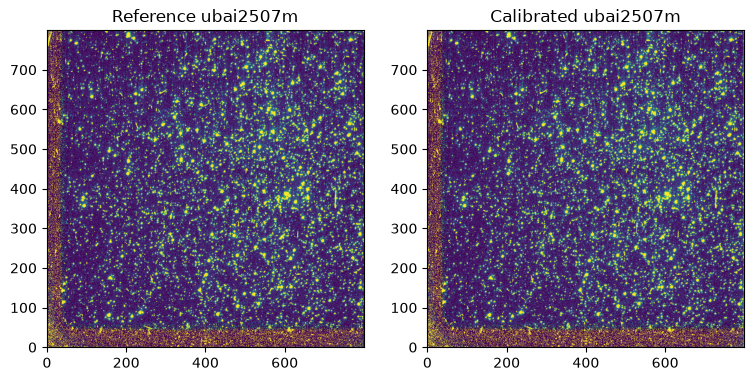

In [ ]:
ubai2507m_aligned = Path("hst-data/F336W/ubai2507m_c0m_aligned.fits")
with fits.open(ubai2507m_aligned) as hdul:
            aligned2507 = hdul[1].data

plt.close('all')
pc_data7 = aligned2507.copy()
pc_data7cal = sky_correct7[0].copy()
fig, (ax, ax1) = plt.subplots(1,2,figsize=(9, 9))
ax.imshow(pc_data7, origin='lower', vmin=0, vmax=5)
ax.set_title("Reference ubai2507m")
ax1.imshow(pc_data7cal, origin='lower', vmin=0, vmax=5)
ax1.set_title("Calibrated ubai2507m")

Text(0.5, 1.0, 'Calibrated ubai2508m')

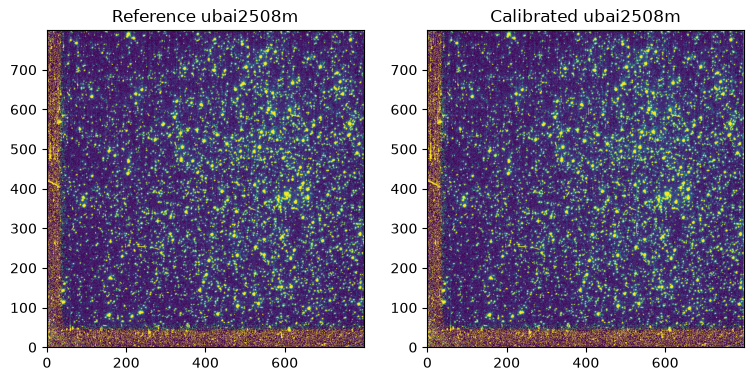

In [ ]:
ubai2508m_aligned = Path("hst-data/F336W/ubai2508m_c0m_aligned.fits")
with fits.open(ubai2508m_aligned) as hdul:
            aligned2508 = hdul[1].data

plt.close('all')
pc_data8 = aligned2508.copy()
pc_data8cal = sky_correct8[0].copy()
fig, (ax, ax1) = plt.subplots(1,2,figsize=(9, 9))
ax.imshow(pc_data8, origin='lower', vmin=0, vmax=5)
ax.set_title("Reference ubai2508m")
ax1.imshow(pc_data8cal, origin='lower', vmin=0, vmax=5)
ax1.set_title("Calibrated ubai2508m")

In [ ]:
def flux(exp_time, PHOTOFLAM, skycorr_data):
    count = skycorr_data/exp_time
    image = count * PHOTOFLAM
    
    
    return image

def magnitude(fluxdata,PHOTZPT):
    magnitude = -2.5*np.log(fluxdata) + PHOTZPT
    return magnitude

PHOTOFLAM = 1.115396e-16
PHOTZPT = -21.1
PHOTPLAM = 3359.474
PHOTBW = 204.4908
ZP_CORR = -0.03288031

In [ ]:
#Convert to flux
aligned_5 = flux(time5, PHOTOFLAM,aligned2505)
mask5p = ~np.isnan(sky_correct5[0])
Cal5 = flux(time5, PHOTOFLAM, sky_correct5[0][mask5p])
ma5= aligned_5.mean()
mc5 =Cal5.mean()
photo5 = [ma5, mc5]
mag5 = magnitude(photo5, PHOTOFLAM)
print(f"The mean flux of the reference data is {ma5}, and of the calibrated data is {mc5}")
print(f"Flux {ma5} magnitude is {mag5[0]}")
print(f"Flux {mc5} magnitude is {mag5[1]}")

The mean flux of the reference data is 3.679999883217123e-19, and of the calibrated data is 3.7260414686551195e-19
Flux 3.679999883217123e-19 magnitude is 106.11551011610126
Flux 3.7260414686551195e-19 magnitude is 106.08442591308084


In [ ]:
aligned_7 = flux(time7, PHOTOFLAM,aligned2507)
mask7p = ~np.isnan(sky_correct7[0])
Cal7 = flux(time7, PHOTOFLAM, sky_correct7[0][mask7p])
ma7= aligned_7.mean()
mc7 =Cal7.mean()
photo7 = [ma7, mc7]
mag7 = magnitude(photo7, PHOTOFLAM)
print(f"The mean flux of the reference data is {ma7}, and of the calibrated data is {mc7}")
print(f"Flux {ma7} magnitude is {mag7[0]}")
print(f"Flux {mc7} magnitude is {mag7[1]}")

The mean flux of the reference data is 5.220530827042014e-19, and of the calibrated data is 5.2742198919171835e-19
Flux 5.220530827042014e-19 magnitude is 105.24129419789571
Flux 5.2742198919171835e-19 magnitude is 105.21571496562358


In [ ]:
aligned_8 = flux(time8, PHOTOFLAM,aligned2508)
mask8p = ~np.isnan(sky_correct8[0])
Cal8 = flux(time8, PHOTOFLAM, sky_correct8[0][mask8p])
ma8= aligned_8.mean()
mc8 =Cal8.mean()
photo8 = [ma8, mc8]
mag8 = magnitude(photo8, PHOTOFLAM)
print(f"The mean flux of the reference data is {ma8}, and of the calibrated data is {mc8}")
print(f"Flux {ma8} magnitude is {mag8[0]}")
print(f"Flux {mc8} magnitude is {mag8[1]}")


The mean flux of the reference data is 8.205201671737678e-19, and of the calibrated data is 8.269164883540667e-19
Flux 8.205201671737678e-19 magnitude is 104.1108711587995
Flux 8.269164883540667e-19 magnitude is 104.09145811096064


array([[ 9.82376502e+01, -9.52581014e+00,  5.33832733e+00, ...,
        -2.07602725e+01, -2.27266671e+01,             nan],
       [ 1.01419002e+02, -1.73207683e+00,  8.41012366e+00, ...,
        -1.24874039e+00,  3.04018371e+00,             nan],
       [-2.79873722e+00, -8.04700915e+00,  3.61103254e+00, ...,
         3.63532503e+01,  1.75037817e+00,             nan],
       ...,
       [-1.38459722e+00, -2.75059437e+00,  2.09690251e+00, ...,
         1.00809419e+00,  2.08584812e+00,             nan],
       [-5.99320248e-01, -4.80052046e+00,  9.69835941e-01, ...,
         2.27934269e+00,  3.25606128e+00,             nan],
       [ 1.30068954e+00, -2.07963647e-03,  1.04297237e+02, ...,
        -2.15702250e+00,  1.12410807e+02,             nan]],
      shape=(800, 800))

(800, 800)

In [ ]:
from scipy.ndimage import maximum_filter


In [ ]:
from scipy.ndimage import gaussian_filter, convolve
filtered_image = gaussian_filter(Cal5 , sigma=1, mode='reflect')
#local_max = maximum_filter(pc_data5cal, size=10)
#local_max_mask = (local_max == pc_data5cal)
#fig, ax = plt.subplots(figsize=(8,8))
#ax.imshow(local_max_mask, origin='lower')
#coordinates = np.argwhere(local_max_mask)
#coordinates
#y, x = coordinates.T
#plt.close('all')
#fig, ax = plt.subplots(figsize=(9, 9))
#flux_sqrt = cutils.transform_by('sqrt', pc_data5cal, pmin=1, pmax=99)
#ax.imshow(flux_sqrt, origin='lower')
# ax.scatter(x, y, marker='+', s=10, color='r')
#sns.scatterplot(x=x, y=y, ax=ax) # optional
#plt.show()
filtered_image.min(), filtered_image.max()
def get_local_max(data, nsize=10):
    """ apply a maximum filter to extract coordinates """
    local_max = maximum_filter(data, size=nsize)
    local_max_mask = (local_max == data)
    coordinates = np.argwhere(local_max_mask)
    print(f"The maximum_filter found {len(coordinates)} possible sources")
    return coordinates

coords1 = get_local_max(aligned2505)
coords2 = get_local_max(sky_correct5[0])

The maximum_filter found 4896 possible sources
The maximum_filter found 4882 possible sources


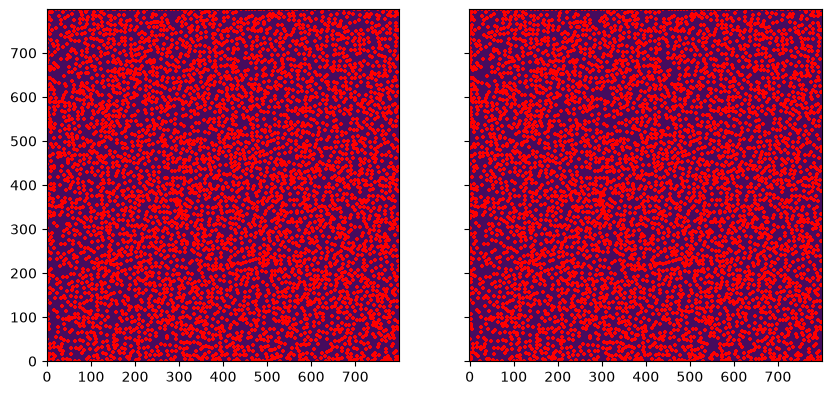

In [ ]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 5), sharex=True, sharey=True)
# sqrt_filtered = cutils.transform_by('sqrt', filtered_image, pmin=1, pmax=99)
ax1.imshow(aligned2505, origin='lower')
ax2.imshow(aligned2505, origin='lower')
ax1.scatter(coords1[:, 1], coords1[:, 0], s=10, marker='+', c='r', label='basic max filter')
ax2.scatter(coords2[:, 1], coords2[:, 0], s=10, marker='+', c='r', label='gaussian filtered max filter')
plt.show()

In [ ]:
def gauss_2d(coords, amp, x0, y0, sigx, sigy):
    """ return a 2d gaussian evaluation """
    y, x = coords
    term1 = (x - x0)**2 / (2 * sigx**2)
    term2 = (y - y0)**2 / (2 * sigy**2)
    g = amp * np.exp(-(term1 + term2))
    return g.ravel()
p0 = [
    aligned_5.max(), # amplitude
    test_coords[1], # x center
    test_coords[0], # y center
    0.5, # sigx
    0.5 # sigy
]
yvals, xvals = np.indices(aligned_5.shape)
yvals
popt, pcov = curve_fit(
    gauss_2d,
    (yvals, xvals),
    aligned_5.ravel(),
    p0=p0
)
popt

array([5.38473627e-17, 3.68681245e+02, 4.70338150e+02, 7.95574685e-01,
       8.05170179e-01])

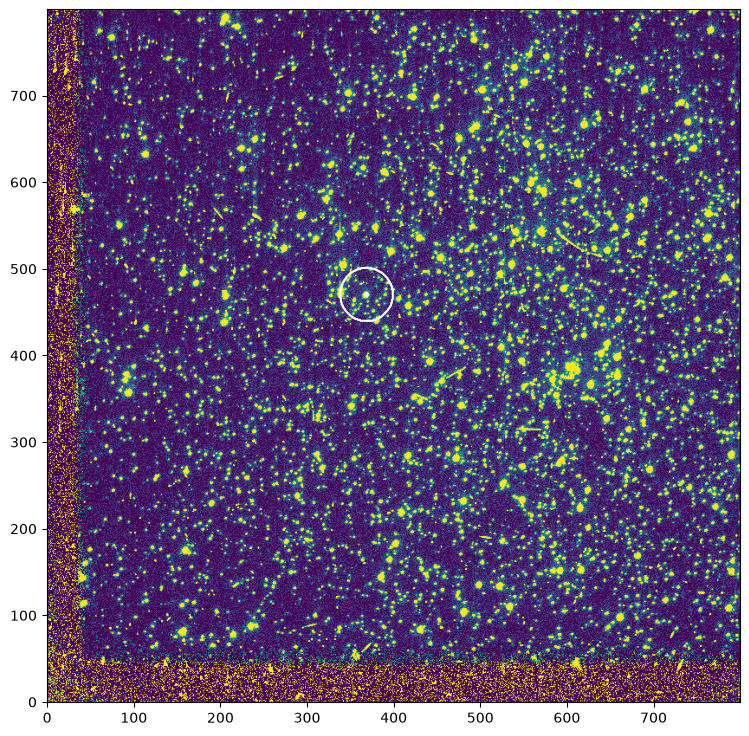

In [ ]:
plt.close('all')
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(aligned2505, origin='lower',vmin=0, vmax=5)
fitted_gaussian = gauss_2d(
    (yvals, xvals),
    *popt
).reshape(aligned2505.shape)
ax.contour(xvals, yvals, fitted_gaussian, levels=5, colors='white', vmin=0, vmax=5)
plt.show()

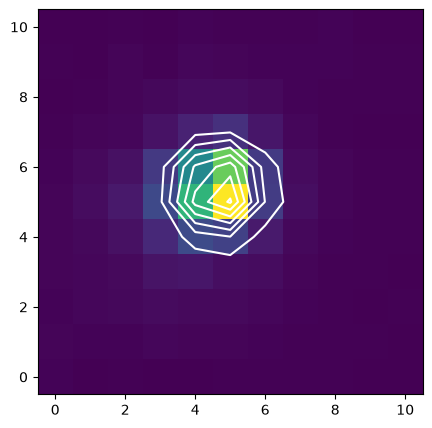

In [ ]:
cutout = cutils.square_aperture(aligned2505, center=[470, 369], box_size=10)
popt, pcov = fit_gauss_2d(cutout)
plt.close('all')
fig, ax = plt.subplots(figsize=(5,5))
ax.imshow(cutout, origin='lower')
yind, xind = np.indices(cutout.shape)
fitted = gauss_2d([yind, xind], *popt).reshape(cutout.shape)
ax.contour(xind, yind, fitted, levels=7, colors='white')
plt.show()


(250.0, 301.0)

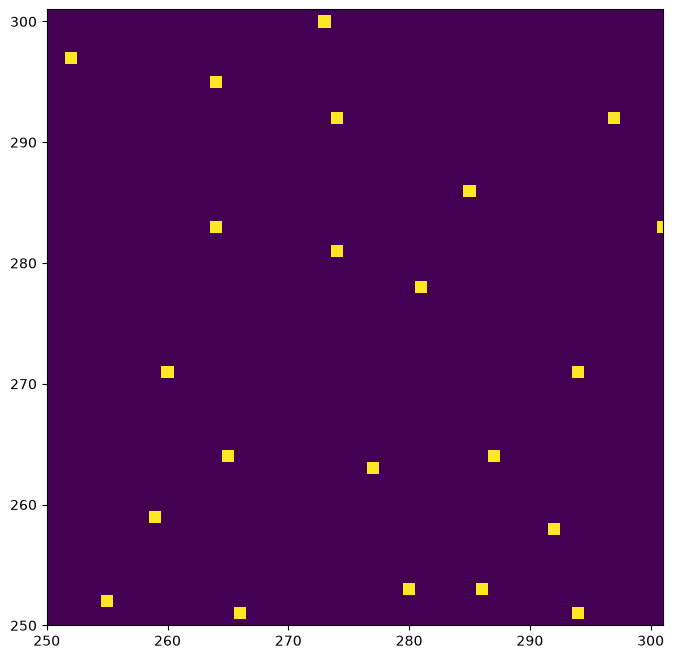

In [ ]:
fig, ax = plt.subplots(figsize=(8,8))
ax.imshow(l_max_mask, origin='lower')
ax.set_xlim(250, 301)
ax.set_ylim(250, 301)

In [ ]:
coordinates = np.argwhere(l_max_mask)
coordinates

array([[  0,  63],
       [  0, 116],
       [  0, 145],
       ...,
       [799, 782],
       [799, 788],
       [799, 795]], shape=(4922, 2))

C:\Users\valer\OneDrive - University College Dublin\Space Detector Laboratory\Assignment2\ccd_utils.py:116: RuntimeWarning: invalid value encountered in scalar divide
  norm = (res - vmin) / (vmax - vmin)


TypeError: Invalid shape () for image data

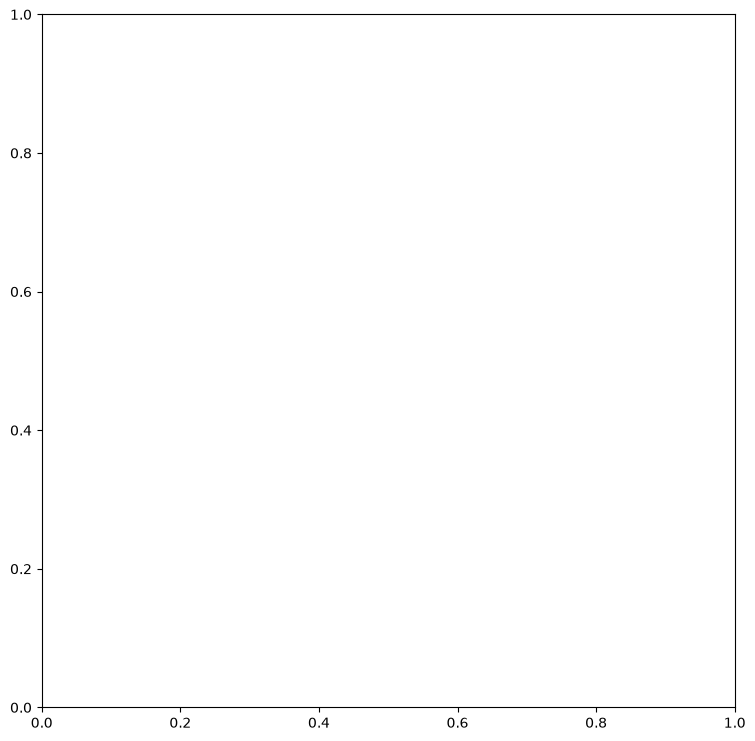

In [ ]:
import ccd_utils as cutils
import seaborn as sns
plt.close('all')
fig, ax = plt.subplots(figsize=(9, 9))
flux_sqrt = cutils.transform_by('sqrt', photo5[0], pmin=1, pmax=99)
ax.imshow(flux_sqrt, origin='lower')
# ax.scatter(x, y, marker='+', s=10, color='r')
sns.scatterplot(x=x, y=y, ax=ax) # optional
plt.show()

In [ ]:
def get_local_max(data, nsize=10):
    """ apply a maximum filter to extract coordinates """
    local_max = maximum_filter(data, size=nsize)
    local_max_mask = (local_max == data)
    coordinates = np.argwhere(local_max_mask)
    print(f"The maximum_filter found {len(coordinates)} possible sources")
    return coordinates

coords1 = get_local_max(photo8[0])
coords2 = get_local_max(data)

The maximum_filter found 1 possible sources
The maximum_filter found 4896 possible sources


TypeError: Invalid shape () for image data

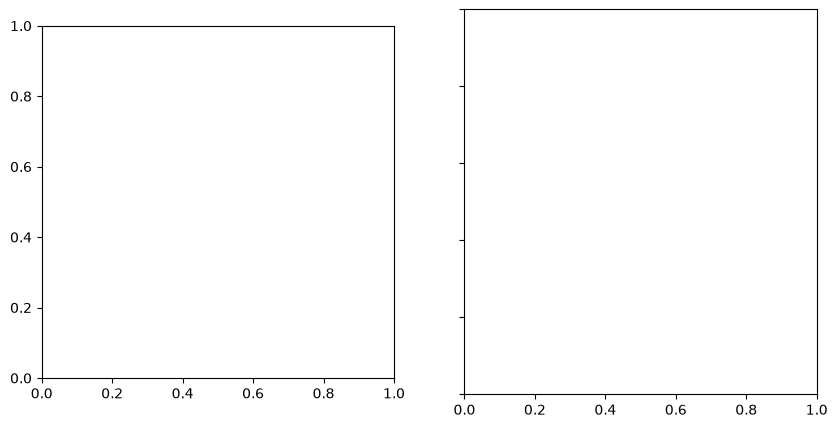

In [ ]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 5), sharex=True, sharey=True)
# sqrt_filtered = cutils.transform_by('sqrt', filtered_image, pmin=1, pmax=99)
ax1.imshow(flux_sqrt, origin='lower')
ax2.imshow(flux_sqrt, origin='lower')
ax1.scatter(coords1[:, 1], coords1[:, 0], s=10, marker='+', c='r', label='basic max filter')
ax2.scatter(coords2[:, 1], coords2[:, 0], s=10, marker='+', c='r', label='gaussian filtered max filter')
plt.show()

In [ ]:
def gauss_2d(coords, amp, x0, y0, sigx, sigy):
    """ return a 2d gaussian evaluation """
    y, x = coords
    term1 = (x - x0)**2 / (2 * sigx**2)
    term2 = (y - y0)**2 / (2 * sigy**2)
    g = amp * np.exp(-(term1 + term2))
    return g.ravel()
sky_correct8

array([[[ 9.82376502e+01, -9.52581014e+00,  5.33832733e+00, ...,
         -2.07602725e+01, -2.27266671e+01,             nan],
        [ 1.01419002e+02, -1.73207683e+00,  8.41012366e+00, ...,
         -1.24874039e+00,  3.04018371e+00,             nan],
        [-2.79873722e+00, -8.04700915e+00,  3.61103254e+00, ...,
          3.63532503e+01,  1.75037817e+00,             nan],
        ...,
        [-1.38459722e+00, -2.75059437e+00,  2.09690251e+00, ...,
          1.00809419e+00,  2.08584812e+00,             nan],
        [-5.99320248e-01, -4.80052046e+00,  9.69835941e-01, ...,
          2.27934269e+00,  3.25606128e+00,             nan],
        [ 1.30068954e+00, -2.07963647e-03,  1.04297237e+02, ...,
         -2.15702250e+00,  1.12410807e+02,             nan]],

       [[ 1.04529217e+03,  2.01481068e+03,  1.98465741e+03, ...,
          1.59473185e+03,  1.82143825e+03,             nan],
        [ 1.02444767e+03,  2.01169253e+03,  2.01070195e+03, ...,
          1.92245871e+03,  1.77298689e

In [ ]:
from scipy.optimize import curve_fit
test_coords = [470, 369]


p0 = [
    sky_correct8[0].max(), # amplitude
    test_coords[1], # x center
    test_coords[0], # y center
    0.5, # sigx
    0.5 # sigy
]
yvals, xvals = np.indices(sky_correct8[0].shape)
popt, pcov = curve_fit(
    gauss_2d,
    (yvals, xvals),
    sky_correct8[0].ravel(),
    
    p0=p0
)

ValueError: array must not contain infs or NaNs

In [ ]:
popt

array([338.6714479 ,   4.68274292,   5.3383665 ,   0.79292712,
         0.80445477])

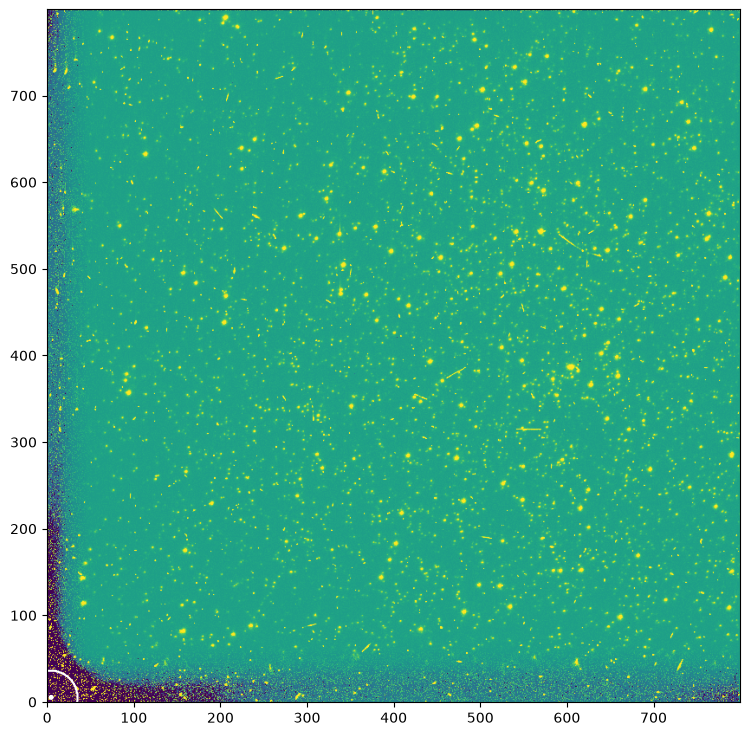

In [ ]:
plt.close('all')
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(flux_sqrt, origin='lower')
fitted_gaussian = gauss_2d(
    (yvals, xvals),
    *popt
).reshape(sky_correct8[0].shape)
ax.contour(xvals, yvals, fitted_gaussian, levels=5, colors='white')
plt.show()

In [ ]:
def fit_gauss_2d(data, init_par=None):
    """ a fitting routine for a 2d gaussian function """

    res = data.copy()
    res[res < 0] = 0.
    if init_par is None:
        amp = res.max() - res.min()
        x0, y0 = moment_1(res)
        sigx, sigy = moment_2(res)
        init_par = [amp, x0, y0, sigx, sigy]

    y, x = np.indices(res.shape)
    popt, pcov = curve_fit(
        gauss_2d,
        (y, x),
        res.ravel(),
        p0=init_par
    )

    return popt, pcov

def moment_1(data):
    """ get the intensity weighted centroid of an image """
    y, x = np.indices(data.shape)
    x0 = np.sum(x * data) / data.sum()
    y0 = np.sum(y * data) / data.sum()
    return x0, y0

def moment_2(data):
    """ get the second moment to estimate the peak width """
    y, x = np.indices(data.shape)
    x0, y0 = moment_1(data)
    sigx = np.sqrt(np.sum(((x - x0)**2) * data) / data.sum())
    sigy = np.sqrt(np.sum(((y - y0)**2) * data) / data.sum())
    return sigx, sigy

In [ ]:
cutout = cutils.square_aperture(sky_correct8[0], center=[470, 369], box_size=10)
popt, pcov = fit_gauss_2d(cutout)

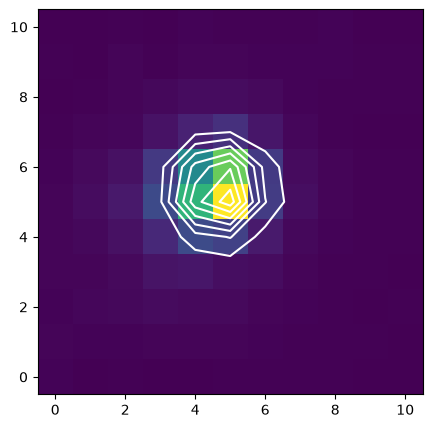

In [ ]:
plt.close('all')
fig, ax = plt.subplots(figsize=(5,5))
ax.imshow(cutout, origin='lower')
yind, xind = np.indices(cutout.shape)
fitted = gauss_2d([yind, xind], *popt).reshape(cutout.shape)
ax.contour(xind, yind, fitted, levels=7, colors='white')
plt.show()